# Importações

In [1]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, make_scorer, matthews_corrcoef
from sklearn.model_selection import cross_val_score
import matplotlib.pyplot as plt

# Criação do modelo Decision Tree

In [2]:

%run 07_divisao_e_balanceamento.ipynb

modelo = DecisionTreeClassifier(
    criterion='gini', 
    max_depth=5,            # Limita a profundidade
    min_samples_split=10,   # Exige um mínimo para dividir
    random_state=42
)
# Treinar
modelo.fit(X_train, y_train)
# Realizar previsões
y_pred = modelo.predict(X_test)
# Avaliar a acurácia
print("Acurácia:", modelo.score(X_test, y_test))


7004 1752
Acurácia: 0.8835616438356164


## Matriz de Confusão

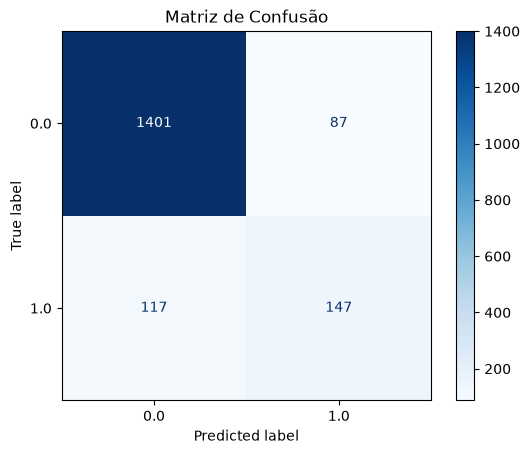

In [3]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo.classes_)
disp.plot(cmap=plt.cm.Blues)

plt.title("Matriz de Confusão")
plt.show()

## Precisão

A precisão é o cálculo por coluna da matriz de confusão é:

| | **Previsão Positiva** | **Previsão Negativa** |
| :--- | :--- | :--- |
| **Real Positivo** | **1401** (Verdadeiro Positivo - $VP$) | **87** (Falso Negativo - $FN$) |
| **Real Negativo** | **117** (Falso Positivo - $FP$) | **147** (Verdadeiro Negativo - $VN$) |

Então o cálculo da previsão é:
- Previsão Positiva: 1401/1401+117 = **92%**
- Previsão Negativa: 147/147+87 = **62%**

## Sensibilidade (Recall)

Enquanto a Precisão é o cálculo por coluna, a sensibildiade é o cálculo pela linha da Matriz de Confusão:

| | **Previsão Positiva** | **Previsão Negativa** |
| :--- | :--- | :--- |
| **Real Positivo** | **1401** (Verdadeiro Positivo - $VP$) | **87** (Falso Negativo - $FN$) |
| **Real Negativo** | **117** (Falso Positivo - $FP$) | **147** (Verdadeiro Negativo - $VN$) |

Portanto:
- Sensibildade Positiva: 1401/1401+87 = **94%**
- Sensibildade Negativa: 147/147+117 = **56%**

# F1 - Score

O F1-Score é uma média entre precisão e sensibilidade. Vamos calcular:

- Previsão Positiva x Sensibilidade Positiva = 0.92 x 0.94 = 0.8648
- Previsão Positiva + Sensibilidade Positiva = 0.92 + 0.94 = 1.86
- F1 Score Positivo = 2 x 0.8642/1.86
- F1 Score Positivo = **93%**
--------
- Previsão Negativa x Sensibilidade Negativa = 0.62 x 0.56 = 0.3472
- Previsão Negativa + Sensibilidade Negativa = 0.62 + 0.56 = 1.18
- F1 Score Negativo = 2 x 0.3472/1.18
- F1 Score Negativo = **58%**

## Mcc

In [4]:
mcc_scorer = make_scorer(matthews_corrcoef)

scores = cross_val_score(modelo, X_train, y_train, cv=5, scoring=mcc_scorer)
print(scores.mean())

0.527492593610441


# Ajuste e Validação Cruzada (k-fold)

Fizemos a validação cruzada com o modelo, segue os resultados:

In [5]:
modelo = DecisionTreeClassifier(random_state=42)
scores = cross_val_score(modelo, X_train, y_train, cv=5, scoring="f1")

print(scores.mean(), scores.std())

0.568926812358682 0.027811033471332642


## Grid Search

In [6]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier
param_grid = {
 "max_depth": [2, 3, 4, 5, 6, None],
 "criterion": ["gini", "entropy"],
 "min_samples_leaf": [1, 5, 10],
}
grid = GridSearchCV(DecisionTreeClassifier(random_state=42),
 param_grid, scoring="f1", cv=5, n_jobs=-1)
grid.fit(X_train, y_train)
print(grid.best_params_)
print(grid.best_score_)
print(grid.score(X_test, y_test))



{'criterion': 'entropy', 'max_depth': 6, 'min_samples_leaf': 10}
0.6302825692355775
0.582995951417004


## Random Search

In [7]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
param_dist = {
 "max_depth": randint(2, 15),
 "criterion": ["gini", "entropy"],
 "min_samples_leaf": randint(1, 20),
}
busca = RandomizedSearchCV(DecisionTreeClassifier(random_state=42),
 param_dist, n_iter=15, scoring="f1",
 cv=5, n_jobs=-1, random_state=42)
busca.fit(X_train, y_train)
print(busca.best_params_, busca.best_score_)
print(busca.score(X_test, y_test))


{'criterion': 'entropy', 'max_depth': 9, 'min_samples_leaf': 3} 0.6141170589455116
0.6264591439688716


# Hiperparametriação com Random Search e Resultados

Como o Random Search teve resultados melhores do que o Grid Search nós decidimos aplicar os parâmetros de acordo com o Random Search:

In [8]:
%run 07_divisao_e_balanceamento.ipynb

modelo_hiperparametrizado = DecisionTreeClassifier(
    criterion='entropy', 
    max_depth=9,         
    min_samples_leaf=3,  
    random_state=42
)
# Treinar
modelo_hiperparametrizado.fit(X_train, y_train)
# Realizar previsões
y_pred = modelo_hiperparametrizado.predict(X_test)
# Avaliar a acurácia
print("Acurácia:", modelo_hiperparametrizado.score(X_test, y_test))


7004 1752


Acurácia: 0.8904109589041096


## Matriz de Confusão após Hiperparametrização

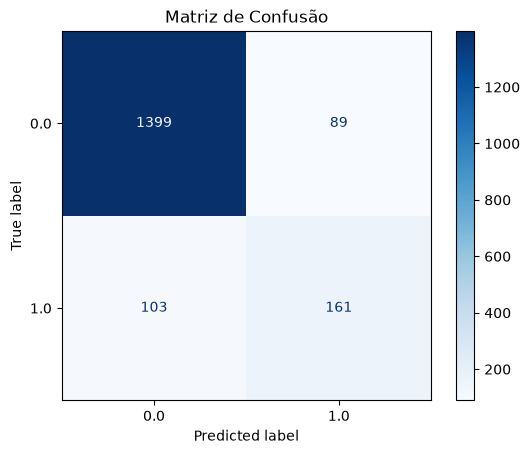

In [9]:

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=modelo_hiperparametrizado.classes_)
disp.plot(cmap=plt.cm.Blues)

plt.title("Matriz de Confusão")
plt.show()

## Precisão após Hiperparametrização

A precisão mudou bastante após a hiperparametrização, pois a Matriz de Confusão :

| | **Previsão Positiva** | **Previsão Negativa** |
| :--- | :--- | :--- |
| **Real Positivo** | **1399** (Verdadeiro Positivo - $VP$) | **89** (Falso Negativo - $FN$) |
| **Real Negativo** | **103** (Falso Positivo - $FP$) | **161** (Verdadeiro Negativo - $VN$) |

Então o cálculo da previsão é:
- Previsão Positiva: 1399/1399+103 = **93%**
- Previsão Negativa: 161/161+89 = **64%**

## Sensibilidade após a Hiperparametrização

A sensibildiade também foi alterada, e vamos encontrar a nova: 

| | **Previsão Positiva** | **Previsão Negativa** |
| :--- | :--- | :--- |
| **Real Positivo** | **1399** (Verdadeiro Positivo - $VP$) | **89** (Falso Negativo - $FN$) |
| **Real Negativo** | **103** (Falso Positivo - $FP$) | **161** (Verdadeiro Negativo - $VN$) |

Então:
- Sensibildade Positiva: 1399/1399+89 = **94%**
- Sensibildade Negativa: 161/161+103 = **61%**

## F1 - Score após Hiperparametrização

- Previsão Positiva x Sensibilidade Positiva = 0.94 x 0.94 = 0.8836
- Previsão Positiva + Sensibilidade Positiva = 0.94 + 0.94 = 1.88
- F1 Score Positivo = 2 x 0.8836/1.88
- F1 Score Positivo = **94%**
----
- Previsão Negativa x Sensibilidade Negativa = 0.64 x 0.61 = 0.3904
- Previsão Negativa + Sensibilidade Negativa = 0.64 + 0.61 = 1.25
- F1 Score Negativo = 2 x 0.3904/1.25
- F1 Score Negativo = **63%**

## Mcc após Hiperparametrização

O Mcc aumentou consideravelmente após a melhoria nos parâmetros do nosso modelo:

In [10]:
mcc_scorer = make_scorer(matthews_corrcoef)

scores = cross_val_score(modelo_hiperparametrizado, X_train, y_train, cv=5, scoring=mcc_scorer)
print(scores.mean())

0.5466983218744674
